In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from matplotlib import rcParams
import plotting_functions

In [3]:

# === Settings ===
base = 9
matplotlib.rcParams.update({
    'font.size': base,
    'axes.labelsize': base,
    'axes.titlesize': base,
    'xtick.labelsize': base,
    'ytick.labelsize': base,
    'legend.fontsize': base,
    'font.family': 'Arial',
})
ms = 6
lw = 2

In [4]:
# Define base directories
# Base paths
base_auc_ = "data_Figs/Fig_AUC_all_subtypes"
base_fix_ = "data_Figs/Fig_Fix_prob_all_subtypes"


In [6]:
# Load Data
data_3HA = plotting_functions.load_data("H3N2", "HA",base_auc_,base_fix_)
data_3NA = plotting_functions.load_data("H3N2", "NA",base_auc_,base_fix_)
data_1HA = plotting_functions.load_data("H1N1", "HA",base_auc_,base_fix_)
data_1NA = plotting_functions.load_data("H1N1", "NA",base_auc_,base_fix_)


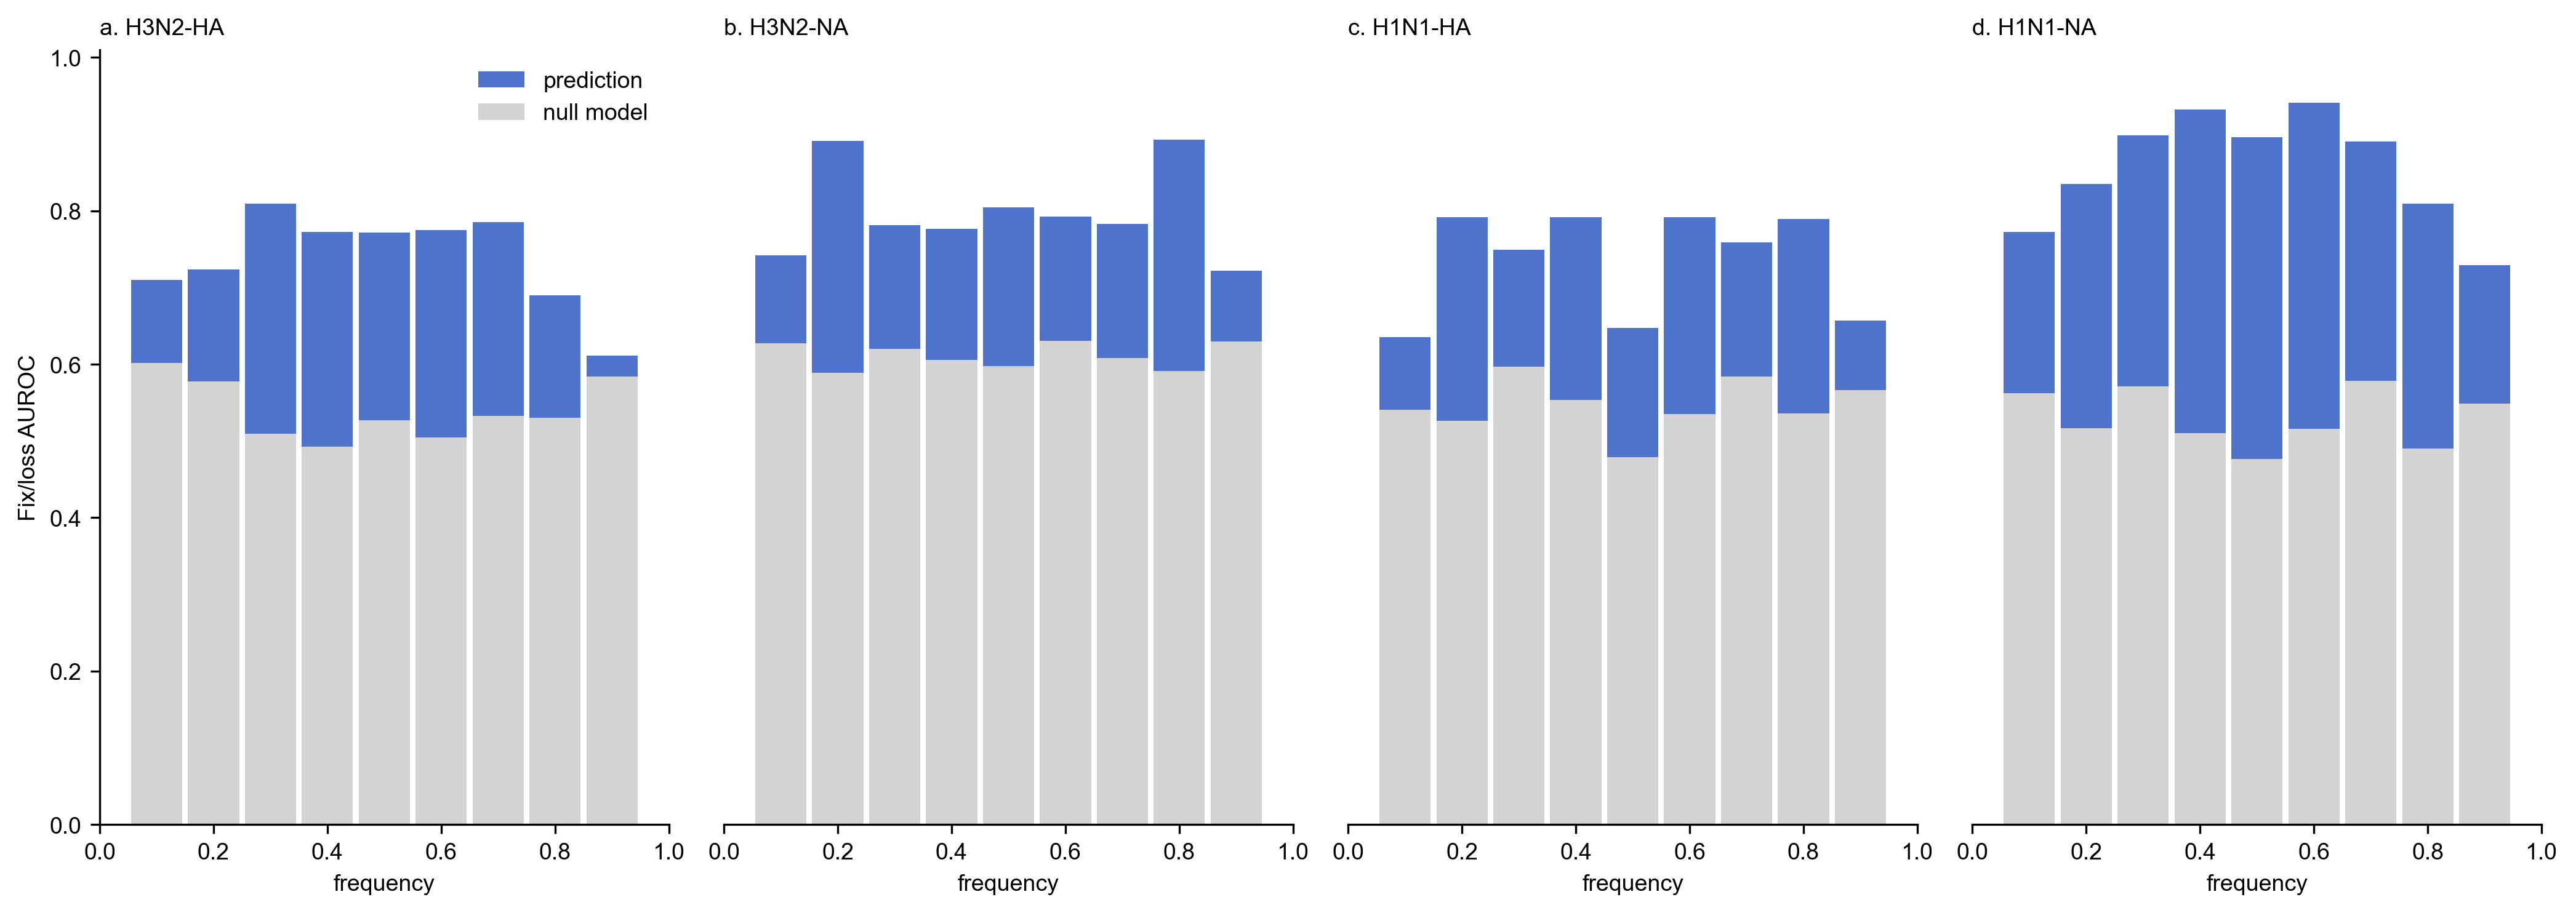

In [7]:

# Create 1 row, 4 column layout

fig, axs = plt.subplots(1, 4, figsize=(14,5), dpi=300)

# List of axes and labels
auc_data = [
    (data_3HA, "a. H3N2-HA"),
    (data_3NA, "b. H3N2-NA"),
    (data_1HA, "c. H1N1-HA"),
    (data_1NA, "d. H1N1-NA"),
]

# Generate AUC plots directly on layout axes
for i, (data, title) in enumerate(auc_data):
    ax = axs[i]
    plotting_functions.plot_auc_bar(data, title, ax=ax)  # <- pass ax explicitly

    # Only keep legend in the first subplot
    if i != 0:
        ax.legend().remove()
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)  # Removes y-axis line
    # Hide y-axis on all but the first
    if i != 0:
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)
    
    # Align title to the left
    ax.set_title(title, loc='left')

# Adjust spacing
fig.tight_layout(pad=1)

# Show or save
fig.savefig("AUC_all_proteins.pdf", bbox_inches="tight")
plt.show()